## Analiza struktury danych i ocena braków

**Cel badania:** ocena średniej zmiany `CHG = Y_T2 − Y_T1` w grupie z czynnikiem (`TRT=1`) i kontrolnej (`TRT=2`) oraz różnicy między grupami, modelem analizy kowariancji.

**Zakres punktu 1:**
1. analiza struktury z podziałem na cechy **ciągłe** i **skokowe**,
2. **graficzna** ocena wyników badania,
3. ocena **zakresu** i **rozkładu** braków danych.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

ROOT = Path.cwd().parent
DATA = ROOT / "data"
CSV_FILE = DATA / "ka01.csv"

sns.set_theme(style="whitegrid", context="notebook")

## 1. Wczytanie danych i definicja ról zmiennych

Role zmiennych zgodnie z projektem badania:

| Zmienna | Typ | Rola |
|---|---|---|
| `y_t1` | ciągła | pomiar w t_1 |
| `y_t2` | ciągła | pomiar w t_2 |
| `x1` | ciągła | cecha stanu początkowego |
| `trt` | skokowa |1 = grupa z czynnikiem, 2 = grupa kontrolna |
| `x2` | skokowa | cecha skokowa stanu początkowego (0/1) |
| `chg` = `y_t2 − y_t1` | ciągła  | zmienna zależna modelu |

Zmienna `chg` powstaje z `y_t2`, więc brak w `y_t2` automatycznie oznacza brak w `chg`. Problem braków dotyczy zatem zmiennej objaśnianej modelu, a więc nie można go pominąć.

In [ ]:
df = pd.read_csv(CSV_FILE)
df["chg"]     = df["y_t2"] - df["y_t1"]
df["trt_lab"] = df["trt"].map({1: "TRT=1 (czynnik)", 2: "TRT=2 (kontrola)"})

CIAGLE  = ["y_t1", "x1", "y_t2", "chg"]
SKOKOWE = ["trt", "x2"]
PAL = {"TRT=1 (czynnik)": "#2a6f97", "TRT=2 (kontrola)": "#c1121f"}

print("Wymiary zbioru:", df.shape)
df.head()

Wymiary zbioru: (805, 7)


,y_t1,x1,trt,x2,y_t2,chg,trt_lab
0,9.632983,55.158388,1,0,7.764858,-1.868124,TRT=1 (czynnik)
1,11.885582,49.207020,1,1,10.669919,-1.215663,TRT=1 (czynnik)
2,10.449324,47.741301,1,1,11.215358,0.766034,TRT=1 (czynnik)
3,9.399263,39.062814,1,0,NaN,NaN,TRT=1 (czynnik)
4,11.186338,49.632284,1,0,9.510397,-1.675941,TRT=1 (czynnik)


## 2. Struktura cech ciągłych

Dla każdej cechy ciągłej liczymy zestaw statystyk oraz miary kształtu rozkładu:
- skośność
- kurtoza

Statystyki `y_t2` i `chg` liczone są tylko na obserwacjach kompletnych.

In [9]:
def opis_ciaglej(s: pd.Series) -> pd.Series:
    # Zestaw statystyk opisowych dla jednej cechy ciągłej (pomija braki)
    s = s.dropna()
    return pd.Series({
        "n": int(s.size),
        "śr": s.mean(), "sd": s.std(ddof=1),
        "min": s.min(), "Q1": s.quantile(.25), "med": s.median(),
        "Q3": s.quantile(.75), "max": s.max(),
        "skośność": stats.skew(s),
        "kurtoza": stats.kurtosis(s),
    })

struktura = df[CIAGLE].apply(opis_ciaglej).T
struktura["braki"] = df[CIAGLE].isna().sum().values
struktura.round(3)

,n,śr,sd,min,Q1,med,Q3,max,skośność,kurtoza,braki
y_t1,805.0,10.886,0.990,7.562,10.231,10.877,11.557,14.772,0.058,0.115,0
x1,805.0,52.435,6.122,32.515,48.467,52.100,56.369,72.258,0.194,0.155,0
y_t2,544.0,10.197,2.483,0.583,8.691,10.359,11.757,17.760,-0.294,0.707,261
chg,544.0,-0.626,2.433,-10.350,-2.066,-0.487,0.967,6.932,-0.385,0.618,261


Wszystkie cechy mają rozkłady bliskie symetrycznym i bez grubych ogonów, zatem brak podstaw do transformacji. `y_t1` i `x1` są kompletne, zaś `y_t2` (i `chg`) mają po 261 braków. Rozstęp `y_t2` jest szeroki, a co za tym, warto zauważyć pojedyncze niskie wartości.

### 2a. Cechy ciągłe w podziale na grupy TRT

In [13]:
for v in ["y_t1", "y_t2", "chg"]:
    print(f"-- {v} wg grup --")
    display(df.groupby("trt_lab")[v].apply(opis_ciaglej).unstack().round(3))

-- y_t1 wg grup --


,n,śr,sd,min,Q1,med,Q3,max,skośność,kurtoza
trt_lab,,,,,,,,,,
TRT=1 (czynnik),380.0,10.86,0.961,7.562,10.254,10.871,11.540,13.314,-0.110,0.025
TRT=2 (kontrola),425.0,10.91,1.016,8.362,10.213,10.907,11.576,14.772,0.178,0.138


-- y_t2 wg grup --


,n,śr,sd,min,Q1,med,Q3,max,skośność,kurtoza
trt_lab,,,,,,,,,,
TRT=1 (czynnik),242.0,11.294,2.076,6.153,9.857,11.433,12.687,17.760,0.025,0.125
TRT=2 (kontrola),302.0,9.318,2.435,0.583,7.961,9.587,10.722,16.584,-0.306,0.911


-- chg wg grup --


,n,śr,sd,min,Q1,med,Q3,max,skośność,kurtoza
trt_lab,,,,,,,,,,
TRT=1 (czynnik),242.0,0.453,2.050,-5.074,-0.962,0.687,1.798,6.932,-0.068,0.126
TRT=2 (kontrola),302.0,-1.490,2.372,-10.350,-2.807,-1.192,0.034,4.338,-0.463,0.628


Zmienna `y_t1` jest niemal identyczna w obu grupach, natomiast średnia `chg` wynosi 0,45 przy czynniku i −1,49 w grupie kontrolnej (różnica wynosi około 1,94). To pewien sygnał efektu zmiennej `TRT`, ale należy podchodzić do niego ostrożnie, gdyż liczony jest na obserwowacjach niepustych imoże być obciążony. Warto zwrócić też uwagę na wyższe `x1` w grupie kontrolnej. Grupy nie są idealnie zbalansowane, co uzasadnia model z kowariantą zamiast prostej różnicy średnich.

## 3. Struktura cech skokowych

Dla cech skokowych podajemy liczności i udziały oraz tabelę krzyżową `trt × x2`.

In [11]:
for v in SKOKOWE:
    t = df[v].value_counts().sort_index()
    print(f"\n{v}:")
    display(pd.DataFrame({"n": t, "%": (t / len(df) * 100).round(2)}))

print("\nTabela krzyżowa trt × x2:")
pd.crosstab(df["trt"], df["x2"], margins=True)


trt:


,n,%
trt,,
1,380,47.2
2,425,52.8



x2:


,n,%
x2,,
0,418,51.93
1,387,48.07



Tabela krzyżowa trt × x2:


x2,0,1,All
trt,,,
1,128,252,380
2,290,135,425
All,418,387,805


Grupy `trt` są zbliżone liczebnie. Zmienna `x2` jest powiązana z `trt` (w grupie czynnika przeważa `x2=1`, w kontrolnej `x2=0`). To sygnał, że `x2` niesie informację o jednostkach i może być użyteczne przy korekcie braków.

## 4. Zakres i rozkład braków danych

Oceniamy:
- zakres - ile braków łącznie i dla zmiennych,
- wzorzec - które komórki brakują,
- rozkład - jak braki rozkładają się względem grup i cech

In [12]:
kol = ["y_t1", "x1", "trt", "x2", "y_t2"]

print("Braki per zmienna:")
miss = df[kol].isna().sum()
display(pd.DataFrame({"n_braków": miss, "%": (miss / len(df) * 100).round(2)}))

print("Braki per obserwacja (liczba brakujących komórek w wierszu):")
display(df[kol].isna().sum(axis=1).value_counts().sort_index())

Braki per zmienna:


,n_braków,%
y_t1,0,0.00
x1,0,0.00
trt,0,0.00
x2,0,0.00
y_t2,261,32.42


Braki per obserwacja (liczba brakujących komórek w wierszu):


0    544
1    261
Name: count, dtype: int64

Braki występują wyłącznie w `y_t2`: 261 z 805 obserwacji = 32,4%. To duży odsetek, zatem analiza wyłącznie na przypadkach kompletnych oznaczałaby utratę  około 1/3 próby. Ponieważ brakuje tylko jednej zmiennej, wzorzec jest jednowymiarowy. W macierzy niezerowa jest jedynie kolumna `y_t2`, a każdy niekompletny wiersz ma dokładnie jeden brak.

### 4a. Wzorzec i kompletność - wizualizacja

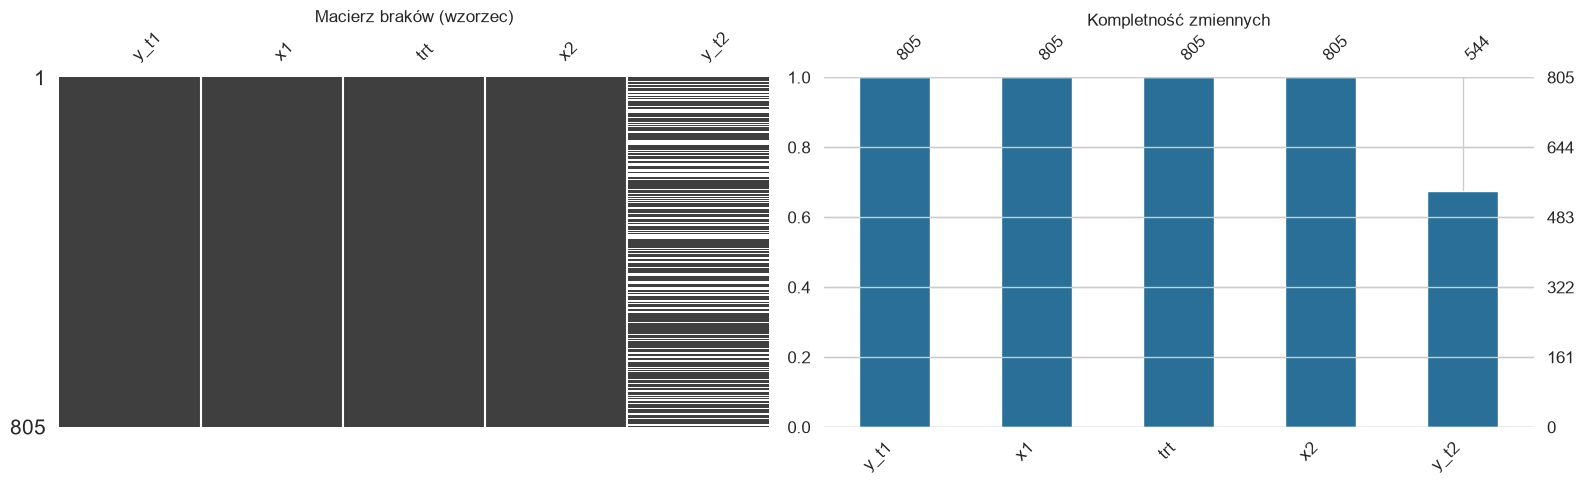

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
msno.matrix(df[kol], ax=ax[0], sparkline=False, fontsize=12)
ax[0].set_title("Macierz braków (wzorzec)")
msno.bar(df[kol], ax=ax[1], fontsize=12, color="#2a6f97")
ax[1].set_title("Kompletność zmiennych")
plt.tight_layout()
plt.savefig(ROOT/"figures"/ "fig1_braki_wzorzec.png", dpi=130, bbox_inches="tight")
plt.show()

### 4b. Rozkład braków `y_t2` względem grup

Rozkład braków y_t2 wg cech skokowych:


,n,braki,%_braków
trt_lab,,,
TRT=1 (czynnik),380.0,138.0,36.32
TRT=2 (kontrola),425.0,123.0,28.94


,n,braki,%_braków
x2,,,
0,418.0,132.0,31.58
1,387.0,129.0,33.33


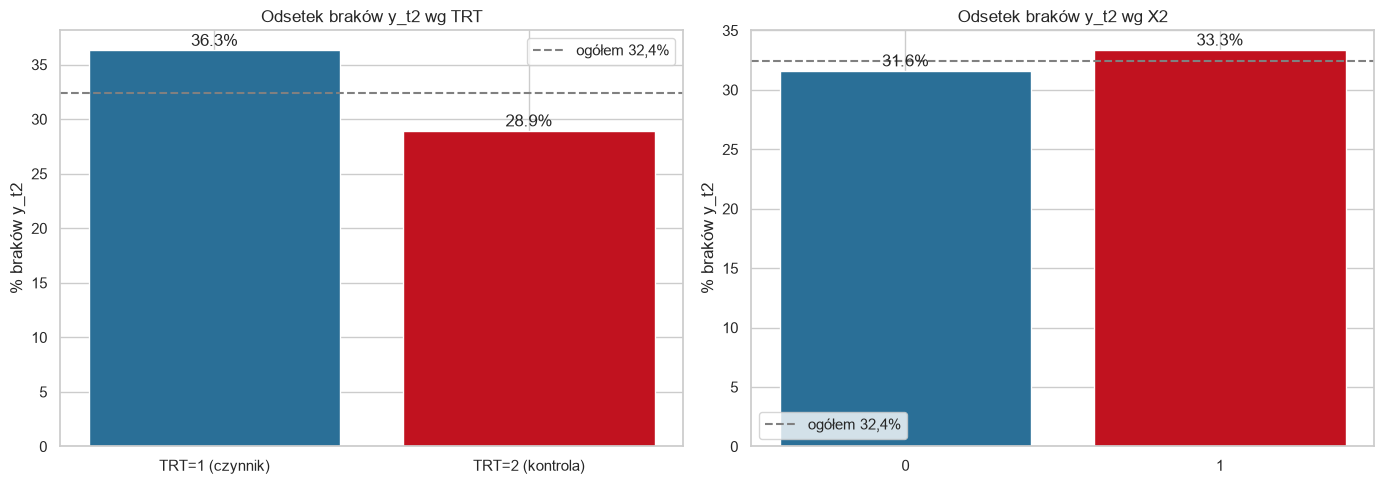

In [16]:
print("Rozkład braków y_t2 wg cech skokowych:")
for v in ["trt_lab", "x2"]:
    g = df.groupby(v)["y_t2"].apply(lambda s: pd.Series(
        {"n": s.size, "braki": s.isna().sum(), "%_braków": round(s.isna().mean() * 100, 2)}))
    display(g.unstack())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (var, lab) in zip(ax, [("trt_lab", "TRT"), ("x2", "X2")]):
    m = df.groupby(var)["y_t2"].apply(lambda s: s.isna().mean() * 100)
    a.bar(m.index.astype(str), m.values, color=["#2a6f97", "#c1121f"])
    a.axhline(df["y_t2"].isna().mean() * 100, ls="--", c="gray", label="ogółem 32,4%")
    a.set_ylabel("% braków y_t2"); a.set_title(f"Odsetek braków y_t2 wg {lab}"); a.legend()
    for i, val in enumerate(m.values):
        a.text(i, val + 0.4, f"{val:.1f}%", ha="center")
plt.tight_layout()
plt.savefig(ROOT/"figures"/ "fig2_braki_grupy.png", dpi=130, bbox_inches="tight")
plt.show()

Odsetek braków `y_t2` wynosi 36,3% w grupie czynnika i 28,9% w kontrolnej, podczas gdy względem `x2` jest jednak bardziej zbliżony. Różnica względem `trt` sugeruje, że mechanizm braków prawdopodobnie nie jest MCAR. Brak zależy przynajmniej od przynależności do grupy. Na podstawie samej próby niestety nie rozstrzygniemy, czy to MAR czy MNAR.

## 5. Graficzna ocena wyników badania

### 5a. Rozkłady cech ciągłych wg grup

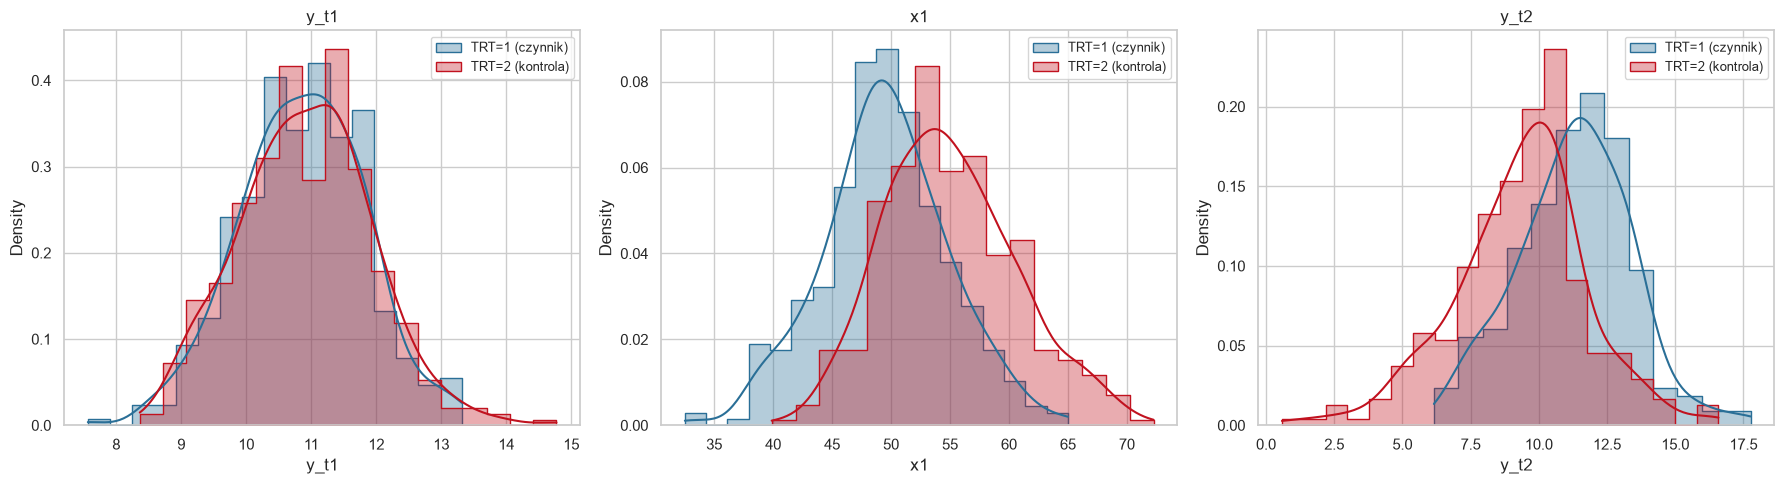

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, v in zip(ax, ["y_t1", "x1", "y_t2"]):
    for lab, g in df.groupby("trt_lab"):
        sns.histplot(g[v].dropna(), ax=a, kde=True, stat="density",
                     color=PAL[lab], alpha=.35, label=lab, element="step")
    a.set_title(v); a.legend(fontsize=9)
plt.tight_layout()
plt.savefig(ROOT/"figures"/ "fig3_rozklady.png", dpi=130, bbox_inches="tight")
plt.show()

### 5b. Wykresy pudełkowe wg grup (widać efekt czynnika)

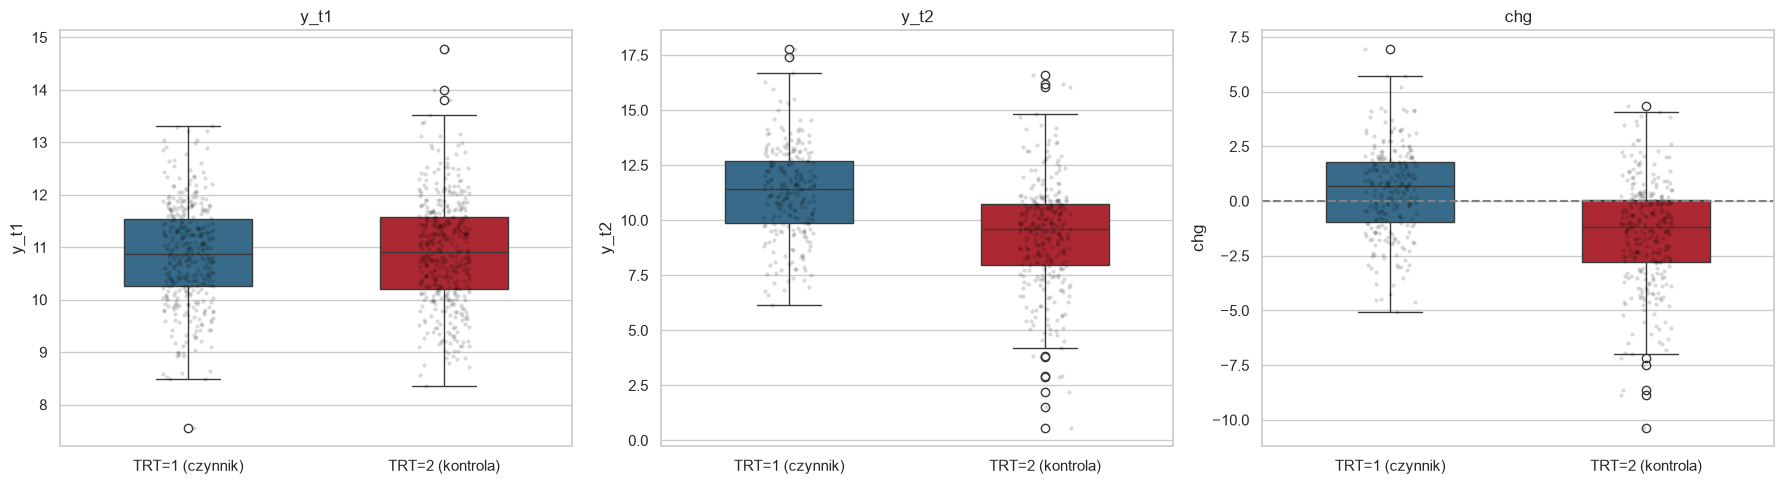

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, v in zip(ax, ["y_t1", "y_t2", "chg"]):
    sns.boxplot(data=df, x="trt_lab", y=v, hue="trt_lab", ax=a,
                palette=PAL, width=.5, legend=False)
    sns.stripplot(data=df, x="trt_lab", y=v, ax=a, color="black", alpha=.15, size=3)
    a.set_title(v); a.set_xlabel("")
    if v == "chg":
        a.axhline(0, ls="--", c="gray")   # linia braku zmiany
plt.tight_layout()
plt.savefig(ROOT/"figures"/ "fig4_boxploty.png", dpi=130, bbox_inches="tight")
plt.show()

Zmienna `y_t1` pokrywa się między grupami, natomiast `y_t2` i `chg` są wyraźnie rozsunięte: mediana `chg` jest dodatnia dla grupy czynnika, lecz ujemna dla kontroli. Pojedyncze bardzo niskie `y_t2`/`chg` w kontroli to obserwacje odstające (outliers).

### 5c. Zależność `y_t2 ~ y_t1` wg grup

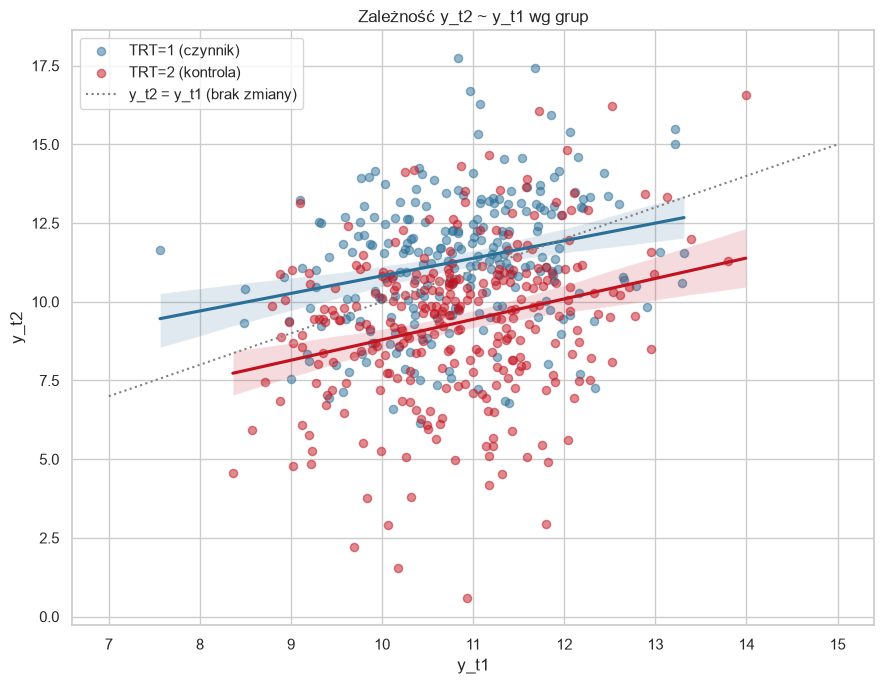

In [19]:
fig, ax = plt.subplots(figsize=(9, 7))
for lab, g in df.groupby("trt_lab"):
    sns.regplot(data=g, x="y_t1", y="y_t2", ax=ax, color=PAL[lab],
                label=lab, scatter_kws=dict(alpha=.5, s=35))
ax.plot([7, 15], [7, 15], ls=":", c="gray", label="y_t2 = y_t1 (brak zmiany)")
ax.set_title("Zależność y_t2 ~ y_t1 wg grup")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT/"figures"/ "fig5_scatter.png", dpi=130, bbox_inches="tight")
plt.show()

W obu grupach występuje dodatnia zależność `y_t2` od `y_t1`. Włączenie `y_t1` do modelu redukuje wariancję resztową. Chmura grupy czynnika leży wyżej, co jest graficznym odpowiednikiem dodatniego $\beta_1$.